In [1]:
import numpy as np
np.set_printoptions(suppress=False)
import mpmath as mp
import math
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap, Normalize
from scipy.linalg import eig, expm
from scipy.integrate import quad
from scipy.optimize import fsolve
from scipy.special import laguerre, jn_zeros, gamma, jv, genlaguerre, hyp1f1, factorial,eval_genlaguerre
from concurrent.futures import ProcessPoolExecutor
from joblib import Parallel, delayed

In [ ]:
# Method 1: Change the working directory directly to the target folder
import os
os.chdir("")

In [2]:
q = 4              # symmetry factor of phase space Hamiltonian
Lambda = 1/4      # effective Planck constant.
Gamma = 1/4

In [3]:
#Gamma = 1.0*1/2 * (10**(-0))/np.abs(Alpha0)**2
alpha2 = fsolve(lambda y0: np.tan(y0) + np.tanh(y0), 2)[0]
Alpha0 = np.sqrt(alpha2)*np.exp(-Gamma)
        #np.exp(1j*2*math.pi*0/10)*1/np.sqrt(2*Lambda))
r = 2 * np.abs(Alpha0*np.exp(Gamma))* np.sqrt(2*Lambda)


In [4]:
def H_T(x, p, Alpha0, Gamma, Lambda, q):

    denominator = np.abs(Alpha0*np.exp(Gamma))**(2 * q)
    T1 = ((x - 1j*p)/np.sqrt(2*Lambda))**q - np.conj(Alpha0*np.exp(Gamma))**q
    T2 = ((x + 1j*p)/np.sqrt(2*Lambda))**q - (Alpha0*np.exp(Gamma))**q
    exp_term = np.exp(-(1 - np.exp(-2*Gamma)) * (x**2 + p**2) / (2*Lambda))
    return (T1 * T2 / denominator) * exp_term
def f_T(k, tau, Alpha0, Lambda, q, Gamma):
    # σ = λ / (1 - e^(-2γ))
    sigma = Lambda / (1 - np.exp(-2 * Gamma))
    denominator = np.abs(np.sqrt(Lambda) * Alpha0  * np.exp(Gamma)) ** (2 * q)
    Term1 = sigma ** (q + 1)* gamma(q + 1)* hyp1f1(q + 1, 1, -sigma * (k**2) / 2.0)
    Term2 = - sigma ** (q + 1)* ((-1j / 2.0)* Alpha0 * np.exp(Gamma)* np.sqrt(2.0 * Lambda) * np.exp(-1j * tau))** q * (k**q) * hyp1f1(q + 1, q + 1, -sigma * (k**2) / 2.0)
    Term3 = - sigma ** (q + 1) * ((-1j / 2.0) * np.conj(Alpha0 * np.exp(Gamma)) * np.sqrt(2.0 * Lambda) * np.exp(1j * tau)) ** q * (k**q) * hyp1f1(q + 1, q + 1, -sigma * (k**2) / 2.0)
    Term4 = sigma * denominator * hyp1f1(1, 1, -sigma * (k**2) / 2.0)
    return (Term1 + Term2 + Term3 + Term4)* (1.0 / denominator) * np.exp(Lambda / 4.0 * (k**2))
kc = np.sqrt((1 - np.exp(-2 * Gamma)) / (4 * Lambda))
print(f_T(1, 1, Alpha0, Lambda, 4, Gamma))
print(kc)

(0.7417960691502558+0j)
0.6272713450233213


In [ ]:

ki = 10**(-10)*kc               # Lower limit of wavenumber integration
kf = 40 * kc                    # Upper limit of wavenumber integration
dk = (kf - ki)/100.0          # Step size for wavenumber

omega0 = 1.0              # The cavity frequency
Delta_tau = 2*np.pi/omega0    # The driving period
tau_i = 0.0* Delta_tau
tau_f = tau_i + Delta_tau
num_time_steps = 1024    # Increase time-evolution accuracy to 1000 steps
d_tau = (tau_f - tau_i) / num_time_steps

t_values_global = np.array([tau_i + (j - 0.5) * d_tau for j in range(1, num_time_steps + 1)])
# ==========================================
# Define the global high-precision Simpson integration grid
# ==========================================
num_intervals = 1024
k_array_global = np.linspace(ki, 4 * kf, num_intervals + 1)
dk_step = (4 * kf - ki) / num_intervals

# Generate Simpson weights: 1, 4, 2, 4, 2, ..., 4, 1
simpson_weights = np.ones(num_intervals + 1)
simpson_weights[1:-1:2] = 4
simpson_weights[2:-2:2] = 2
simpson_weights *= (dk_step / 3.0)
beta_d = 1/100                # The Driving amplitude
Np = 16
def Psi_code(q, l, alpha):
    psi_n = np.array([
        np.exp(-0.5 * np.abs(alpha)**2) * (alpha ** (n - 1)) / np.sqrt(factorial(n - 1))
        * (1 if ((n - 1 + l) % q == 0) else 0)
        for n in range(1, Np + 1)
    ], dtype=complex)

    P_psi = np.sum(np.abs(psi_n)**2)

    return psi_n / np.sqrt(P_psi)
Delta_tau

6.283185307179586

In [6]:
def Psi_code(q, l, alpha):
    psi_n = np.array([
        np.exp(-0.5 * np.abs(alpha)**2) * (alpha ** (n - 1)) / np.sqrt(factorial(n - 1))
        * (1 if ((n - 1 + l) % q == 0) else 0)
        for n in range(1, Np + 1)
    ], dtype=complex)

    P_psi = np.sum(np.abs(psi_n)**2)

    return psi_n / np.sqrt(P_psi)
Psi_codel = np.column_stack([Psi_code(q, l, Alpha0 * np.exp(Gamma)) for l in range(q)])


In [7]:
def compute_TH(q, Alpha0, Gamma, Np):
    TH = np.zeros((Np, Np), dtype=complex)
    abs_Alpha0 = abs(Alpha0)
    for n in range(1, Np+1):
        for m in range(1, Np+1):
            exp_factor = np.exp(-Gamma * ((n-1) + (m-1)))

            # Term1: Only nonzero if n==m and n-1>=q and m-1>=q.
            term1 = 0
            if (n-1) >= q and (m-1) >= q and (n == m):
                term1 = np.sqrt(factorial(n-1) / factorial(n-1 - q)) \
                        * np.sqrt(factorial(m-1) / factorial(m-1 - q))

            # Term2: Nonzero if (n-1)>=q and m == n - q.
            term2 = 0
            if (n-1) >= q and (m == n - q):
                term2 = np.sqrt(factorial(n-1) / factorial(n-1 - q)) * (Alpha0 ** q)

            # Term3: Nonzero if (m-1)>=q and n == m - q.
            term3 = 0
            if (m-1) >= q and (n == m - q):
                term3 = np.sqrt(factorial(m-1) / factorial(m-1 - q)) * (np.conjugate(Alpha0 ** q))

            # Term4: Nonzero if n==m.
            term4 = 0
            if n == m:
                term4 = abs_Alpha0 ** (2 * q)

            TH[n-1, m-1] = (1 / (abs_Alpha0 ** (2 * q))) * exp_factor * (term1 - term2 - term3 + term4)

    return TH

def compute_TU(TH, Lambda):
    """
    Compute the unitary time evolution operator:
      TU = expm( - (i / Lambda) * TH * 2π )
    """
    return expm(-1j / Lambda * TH * 2 * np.pi)

def compute_fidelity(TH, Psi_codel, Lambda):
    """
    Compute fidelity:
      F = Abs[ (Psi_codel)† . (TU . Psi_codel) ]
    where TU = MatrixExp[-(i/Λ)*TH*2π].
    Returns the absolute values of the elements of the matrix product.
    """
    TU = compute_TU(TH, Lambda)
    result = np.dot(np.conjugate(Psi_codel).T, np.dot(TU, Psi_codel))
    return np.abs(result)

TH = compute_TH(q, Alpha0, Gamma, Np)
print("Target Hamiltonian in Fock representation:")
print(TH)

print("\nTH . Psi_codel:")
print(np.dot(TH, Psi_codel))

TU = compute_TU(TH, Lambda)
print("\nUnitary time evolution operator (TU):")
print(TU)

print("\nTU . Psi_codel:")
print(np.dot(TU, Psi_codel))

fidelity_matrix = compute_fidelity(TH, Psi_codel, Lambda)
print("\nFidelity of states after the action of TU:")
print(fidelity_matrix)

Target Hamiltonian in Fock representation:
[[ 1.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j
  -0.87586233+0.j  0.        +0.j  0.        +0.j  0.        +0.j
   0.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j
   0.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.60653066+0.j  0.        +0.j  0.        +0.j
   0.        +0.j -1.18788284+0.j  0.        +0.j  0.        +0.j
   0.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j
   0.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.36787944+0.j  0.        +0.j
   0.        +0.j  0.        +0.j -1.24792072+0.j  0.        +0.j
   0.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j
   0.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.        +0.j  0.22313016+0.j
   0.        +0.j  0.        +0.j  0.        +0.j -1.15618718+0.j
   0.        +0.j  0.        +

##### The Unitary evolution operactor
the following one is about each time step and the UF one is one Floquet period

In [8]:
def H(n, m, tau):
    total = 0.0
    if m >= n:
        T0 = np.sqrt(factorial(n-1) / factorial(m-1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(- (Lambda / 4) * k**2 - 1j * (m - n) * tau)
            T2 = genlaguerre(n - 1, m - n)((Lambda / 2) * k**2)
            T3 = f_T(k, tau, Alpha0, Lambda, q, Gamma)
            T4 = (np.sqrt(Lambda / 2) * 1j * k) ** (m - n)
            total += weight * (k * T1 * T2 * np.real(T3 * T4) * T0)
        return total
    else:
        T0 = np.sqrt(factorial(m-1) / factorial(n-1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(- (Lambda / 4) * k**2 - 1j * (m - n) * tau)
            T2 = genlaguerre(m - 1, n - m)((Lambda / 2) * k**2)
            T3 = f_T(k, tau, Alpha0, Lambda, q, Gamma)
            T4 = (np.sqrt(Lambda / 2) * 1j * k) ** (n - m)
            total += weight * (k * T1 * T2 * np.real(T3 * T4) * T0)
        return total
print(H(1,3,1),H(3,1,1))


(1.1645328973595692+2.544550802810092j) (1.1645328973595692-2.544550802810092j)


In [ ]:
#Harmonics of Rotating-Frame driving potential
def Hl(n, m, l):
    def integrand_real(tau):
        return np.real(H(n, m, tau) * np.exp(-1j * l * tau))
    def integrand_imag(tau):
        return np.imag(H(n, m, tau) * np.exp(-1j * l * tau))

    real_part, _ = quad(integrand_real, 0, 2 * math.pi, epsabs=1e-10, epsrel=1e-10)
    imag_part, _ = quad(integrand_imag, 0, 2 * math.pi, epsabs=1e-10, epsrel=1e-10)


    return 0.5 / math.pi * (real_part + 1j * imag_part)

print(Hl(1,3,1))

In [ ]:
import numpy as np
from joblib import Parallel, delayed
from tqdm.auto import tqdm  # Import the tqdm progress bar

lmax = 30

def generate_HL_parallel_joblib(lmax, Np, Hl, n_jobs=-1):
    l_values = range(0, lmax + 1)
    total_tasks = (lmax + 1) * Np * Np  # Compute the total number of tasks for the progress bar

    # Define all the tasks
    jobs = (
        delayed(Hl)(nn, mm, l)
        for l in l_values
        for nn in range(1, Np + 1)
        for mm in range(1, Np + 1)
    )

    # Key change: use return_as="generator" so tasks are returned as a generator and consumed with tqdm
    results_generator = Parallel(n_jobs=n_jobs, return_as="generator")(jobs)

    # Wrap the generator with tqdm to show progress
    HL = list(tqdm(results_generator, total=total_tasks, desc="Computing HL"))

    return np.array(HL, dtype=np.complex128).reshape((lmax + 1, Np, Np))

HL = generate_HL_parallel_joblib(lmax, Np, Hl, n_jobs=-1)

In [9]:
l = 0
lmax = len(HL)
print(HL[l])

NameError: name 'HL' is not defined

In [ ]:
import numpy as np
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import scipy.io as sio # For exporting to a MATLAB/Mathematica-readable format

# ... [keep the original HL generation code] ...
# HL = generate_HL_parallel_joblib(lmax, Np, Hl, n_jobs=-1)

# Save the matrix as a .npy file
np.save("HL_matrix.npy", HL)
print("Matrix successfully saved as HL_matrix.npy")

c:\Users\21981\.conda\envs\py313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'HL' is not defined

In [ ]:
HL = np.load("HL_matrix.npy")

[[ 1.00010108e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
   3.29704039e-17-6.29151194e-16j  0.00000000e+00+0.00000000e+00j
  -8.75862331e-01+1.97320527e-16j  0.00000000e+00+0.00000000e+00j
   1.09457173e-16+5.00516628e-17j  0.00000000e+00+0.00000000e+00j
   9.95297594e-17-5.70845799e-17j  0.00000000e+00+0.00000000e+00j
   3.42067787e-17+1.63299917e-17j  0.00000000e+00+0.00000000e+00j
  -3.81368114e-17+2.39287047e-17j  0.00000000e+00+0.00000000e+00j
   3.40245393e-18-2.30039035e-17j  0.00000000e+00+0.00000000e+00j]
 [ 0.00000000e+00+0.00000000e+00j  6.06640091e-01+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j -9.33081624e-18-3.49858179e-16j
   0.00000000e+00+0.00000000e+00j -1.18788284e+00+3.50661889e-16j
   0.00000000e+00+0.00000000e+00j  2.00652737e-16+5.16765372e-17j
   0.00000000e+00+0.00000000e+00j  1.74421024e-16-7.85754765e-17j
   0.00000000e+00+0.00000000e+00j  4.11290116e-17+3.37207067e-17j
   0.00000000e+00+0.00000000e+00j -6.74915852e-17+4.55753812e-17j
   0.0000

In [12]:
def HF1(t0):
    temp = 0
    # Loop over l=1,...,lmax-1 (note: Python's range(1, lmax) means 1 to lmax-1)
    for l in range(1, lmax):
        # First term: 1/(2*l)*( HL[l] * HL[l]† - HL[l]† * HL[l] )
        term1 = (HL[l] @ HL[l].conj().T - HL[l].conj().T @ HL[l]) * (1 / (2 * l))
        # Second term: 1/l*( HL[l]† * HL[0] - HL[0] * HL[l]† ) * Exp[i*l*omega0*t0]
        term2 = (HL[l].conj().T @ HL[0] - HL[0] @ HL[l].conj().T) * (1 / l)
        sum_term = term1 + term2 * np.exp(1j * l * omega0 * t0)
        temp += sum_term
    temp *= (1 / (Lambda * omega0))
    # Note: here we return temp + temp† (conjugate transpose)
    return temp + temp.conj().T

# Compute the result at t0 = 0
HF1t0 = HF1(t0=0)
print(HF1t0)

[[  4.80798169+0.00000000e+00j   0.        +0.00000000e+00j
    2.85677495+1.43726323e-15j   0.        +0.00000000e+00j
   -1.70359724-3.98572722e-15j   0.        +0.00000000e+00j
    9.05857306-1.02978743e-14j   0.        +0.00000000e+00j
    4.20556045+2.18902487e-15j   0.        +0.00000000e+00j
    1.21588061-4.60370136e-15j   0.        +0.00000000e+00j
   -0.76353589-1.23470689e-15j   0.        +0.00000000e+00j
    0.27878269+9.25038331e-16j   0.        +0.00000000e+00j]
 [  0.        +0.00000000e+00j   2.70586503+0.00000000e+00j
    0.        +0.00000000e+00j  -0.61864324+2.24460664e-15j
    0.        +0.00000000e+00j  -2.20417052+1.47908571e-15j
    0.        +0.00000000e+00j  18.75801502-1.63999997e-14j
    0.        +0.00000000e+00j   2.99691944+5.90632023e-15j
    0.        +0.00000000e+00j   1.34781522-9.07259226e-15j
    0.        +0.00000000e+00j  -1.10242178-2.84609546e-15j
    0.        +0.00000000e+00j   0.52145697+1.15071276e-15j]
 [  2.85677495-1.43726323e-15j   0.   

In [13]:
def fnm(n, m, Lambda, k, tau):
    if n >= m:
        term1 = math.sqrt(math.factorial(n) / math.factorial(m))
        term2 = np.exp((Lambda/4 * k ** 2 + 1j * (m - n) * tau))
        term3 = (-1j) ** (n-m) * 2 ** ((m - n)/2) * (k ** (n - m)) * (Lambda ** ((1 + (n - m) / 2)))
        term4 = (1 / gamma(1 - m + n)) * hyp1f1(1 + n, 1 - m + n, -k ** 2 *Lambda/2)
        return term1 * term2 * term3 * term4
    else:
        term1 = math.sqrt(math.factorial(m) / math.factorial(n))
        term2 = np.exp((Lambda/4 * k ** 2 + 1j * (n - m) * tau))
        term3 = (-1j) ** (m-n) * 2 ** ((n - m)/2) * ((-k) ** (m - n)) * (Lambda ** ((1 + (m - n) / 2)))
        term4 = (1 / gamma(1 - n + m)) * hyp1f1(1 + m, 1 - n + m, -k ** 2 *Lambda/2)
        return (term1 * term2 * term3 * term4).conj()
print(fnm(1, 2, 0.25, 2, 1))

(0.12287592410629804-0.0788977235447612j)


In [14]:
def fHF1(k, tau):
    result = 0
    for n in range(Np):
        for m in range(Np):
            result += (fnm(n, m, Lambda, k, tau) * HF1t0[n, m])
    return result
print(fHF1(1, 1),HF1t0[1,1],Np)

(-11.825295908551611+6.106226635438361e-16j) (2.705865027541693+0j) 16


In [ ]:
def MfT():
    MfT = []
    for k in k_array_global:
        row = [f_T(k, tau, Alpha0, Lambda, q, Gamma) for tau in t_values_global]
        MfT.append(row)
    return np.array(MfT)
MfT = MfT()
MfT[71]

In [ ]:
def Mf1():
    Mf1 = []
    for k in k_array_global:
        row = [fHF1(k, tau) for tau in t_values_global]
        Mf1.append(row)
    return np.array(Mf1)
Mf1 = Mf1()
Mf1[71]

In [ ]:
MfT1 = beta_d * MfT - (beta_d**2) * Mf1
print(MfT1)

##### Redefine the NcFT coefficients  with  discretised  data


In [ ]:
def fT1(i_k, tau, Alpha0, Lambda, q, Gamma, MfT1):
    # Subtract 0.5 * d_tau to align exactly with the midpoint grid
    i_tau = int(round((tau - tau_i - 0.5 * d_tau) / d_tau)) % MfT1.shape[1]
    return MfT1[i_k, i_tau]

In [ ]:
def HT1(n, m, tau, MfT1):
    total = 0.0
    if m >= n:
        T0 = np.sqrt(factorial(n - 1) / factorial(m - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda/4)*k**2 - 1j*(m - n)*tau)
            T2 = genlaguerre(n - 1, m - n)((Lambda / 2) * k**2)
            T3 = fT1(idx, tau, Alpha0, Lambda, q, Gamma, MfT1) # Pass the index idx directly
            T4 = (np.sqrt(Lambda/2) * 1j * k)**(m - n)
            total += weight * (k * T1 * T2 * np.real(T3*T4) * T0)
        return total
    else:
        T0 = np.sqrt(factorial(m - 1) / factorial(n - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda/4)*k**2 - 1j*(m - n)*tau)
            T2 = genlaguerre(m - 1, n - m)((Lambda / 2) * k**2)
            T3 = fT1(idx, tau, Alpha0, Lambda, q, Gamma, MfT1) # Pass the index idx directly
            T4 = (np.sqrt(Lambda/2) * 1j * k)**(n - m)
            total += weight * (k * T1 * T2 * np.real(T3*T4) * T0)
        return total


##### Unitary  evoltuion  operactor  of  each  time  step .

# second-order Floquet-Magnus term

In [ ]:
import numpy as np
from scipy.special import genlaguerre, factorial
import math
from tqdm import tqdm
fact = factorial(np.arange(Np))
laguerres = {}
for n0 in range(Np):
    for m0 in range(Np):
        if m0 >= n0:
            laguerres[(n0, m0)] = genlaguerre(n0, m0 - n0)
        else:
            laguerres[(n0, m0)] = genlaguerre(m0, n0 - m0)

# ---------------------------
# fHF1 single-point evaluation
# ---------------------------
def fHF1_single(k, tau):
    k = float(k); tau = float(tau)
    try:
        n_idx = np.arange(Np)
        m_idx = np.arange(Np)
        n_grid, m_grid = np.meshgrid(n_idx, m_idx, indexing='ij')
        vals = fnm(n_grid, m_grid, Lambda, k, tau) * HF1t0
        return np.sum(vals)
    except Exception:
        tot = 0+0j
        for n in range(Np):
            for m in range(Np):
                tot += fnm(n, m, Lambda, k, tau) * HF1t0[n, m]
        return tot

# ---------------------------
# Precompute the fHF1 table (Ntau x Nk)
# ---------------------------
def precompute_fHF1_table(k_values, tau_values):
    Nk = len(k_values)
    Ntau = len(tau_values)
    table = np.zeros((Ntau, Nk), dtype=np.complex128)

    # Use tqdm to visualize the tau progress
    for i, tau in enumerate(tqdm(tau_values, desc="Precomputing fHF1 table")):
        for j, k in enumerate(k_values):
            table[i, j] = fHF1_single(k, tau)
    return table

# ---------------------------
# Construct vectorized V1(τ)
# ---------------------------
def V1_tau_from_table(n, m, tau_values, k_values, fHF1_table):
    n0 = n - 1
    m0 = m - 1
    prefactor = dk / 2.0
    Nk = k_values.size
    Ntau = tau_values.size

    if m >= n:
        T0 = math.sqrt(fact[n0] / fact[m0])
        exponent = m - n
    else:
        T0 = math.sqrt(fact[m0] / fact[n0])
        exponent = n - m

    gamma_k = np.exp(-(Lambda / 4.0) * k_values**2)      # (Nk,)
    T2_k = laguerres[(n0, m0)]((Lambda / 2.0) * k_values**2)  # (Nk,)
    T4_k = (np.sqrt(Lambda / 2.0) * 1j * k_values) ** exponent   # (Nk,)

    phase = np.exp(-1j * (m - n) * tau_values)[:, None]  # (Ntau,1)
    T1 = gamma_k[None, :] * phase  # (Ntau, Nk)
    T3 = fHF1_table                 # (Ntau, Nk)
    integrand = k_values[None, :] * T1 * T2_k[None, :] * np.real(T3 * T4_k[None, :]) * T0
    # Key change: multiply by the Simpson weights instead of the original np.sum * prefactor
    V_tau = np.sum(integrand * simpson_weights[None, :], axis=1)
    return V_tau

# ---------------------------
# FFT computation of the l coefficients
# ---------------------------
def compute_V1L_fft_for_pair_with_table(n, m, lmax, k_values, tau_values, fHF1_table):
    V_tau = V1_tau_from_table(n, m, tau_values, k_values, fHF1_table)
    Ntau = len(tau_values)
    coeffs = np.fft.fft(V_tau) / float(Ntau)
    return coeffs[:(lmax + 1)]

# ---------------------------
# Generate the full V1L (lmax+1, Np, Np) in parallel with progress display
# ---------------------------
def generate_V1L_fft_all_final(lmax, Np, Ntau=512):
    k_values = k_array_global  # Strictly reuse the global grid!
    tau_values = np.linspace(0.0, 2.0*np.pi, Ntau, endpoint=False)

    print("Step 1: Precomputing fHF1 table ...")
    fHF1_table = precompute_fHF1_table(k_values, tau_values)

    print("Step 2: Computing V1L FFT coefficients ...")
    pairs = [(n, m) for n in range(1, Np+1) for m in range(1, Np+1)]

    # Use tqdm to show the (n,m) progress
    results = Parallel(n_jobs=-1, backend='threading')(
        delayed(lambda p: compute_V1L_fft_for_pair_with_table(p[0], p[1], lmax, k_values, tau_values, fHF1_table))
        (p) for p in tqdm(pairs, desc="Processing (n,m) pairs")
    )

    arr = np.array(results, dtype=np.complex128).reshape((Np, Np, lmax+1))
    V1L = np.transpose(arr, (2, 0, 1)).copy()  # shape (lmax+1, Np, Np)
    return V1L

lmax = 30
V1L = generate_V1L_fft_all_final(lmax, Np, Ntau=512)
print(V1L.shape)

In [ ]:
import scipy.io as sio # For exporting to a MATLAB/Mathematica-readable format

# ... [keep your original V1L generation code] ...
# lmax = 30
# V1L = generate_V1L_fft_all_final(lmax, Np, Ntau=512)
# print(V1L.shape)

# ==========================================
# Export the V1L matrix
# ==========================================
np.save("V1L_matrix.npy", V1L)
print("V1L matrix successfully saved as V1L_matrix.npy")

In [ ]:
V1L = np.load("V1L_matrix.npy")
print("V1L matrix loaded successfully, shape:", V1L.shape)

成功从本地读取 V1L 矩阵，形状为: (31, 16, 16)


In [ ]:
import numpy as np

# Get the maximum truncation orders
lmax_HL = len(HL)
lmax_V1 = len(V1L)

# ==========================================
# Helper function 1: get the 0th-order harmonic matrix V^(0)_l
# Out-of-bounds protection added: beyond the truncation order, the high-frequency component is treated as decayed to 0
# ==========================================
def get_HL(l):
    if abs(l) >= lmax_HL:
        return np.zeros((Np, Np), dtype=np.complex128)

    if l >= 0:
        return HL[l]
    else:
        return HL[-l].conj().T

# ==========================================
# Helper function 2: get the 1st-order harmonic matrix V^(1)_l
# Includes the necessary minus sign, with out-of-bounds protection added
# ==========================================
def get_V1L(l):
    if abs(l) >= lmax_V1:
        return np.zeros((Np, Np), dtype=np.complex128)

    if l >= 0:
        return -V1L[l]
    else:
        return -V1L[-l].conj().T

def comm(A, B):
    return A @ B - B @ A

# ==========================================
# Compute HF12 (pure second-order expansion, corresponding to the 8 terms in Appendix B of the paper)
# ==========================================
def HF12(t0):
    temp = np.zeros((Np, Np), dtype=np.complex128)

    # Build the full positive-and-negative range excluding 0, e.g.: [-lmax+1, ..., -1, 1, ..., lmax-1]
    l_range = [l for l in range(-lmax_HL+1, lmax_HL) if l != 0]

    for l in l_range:
        V_minus_l = get_HL(-l)
        V_0       = get_HL(0)
        V_l       = get_HL(l)

        # =========================================================
        # Single-sum terms (terms 1 and 3 of the formula)
        # =========================================================
        # 1) + [V_-l, [V_0, V_l]] / (2 l^2)
        temp += comm(V_minus_l, comm(V_0, V_l)) / (2 * l**2)

        # 3) - [V_0, [V_0, V_-l]] / l^2 * e^{i l Ω t0}
        temp -= comm(V_0, comm(V_0, V_minus_l)) / (l**2) * np.exp(1j * l * omega0 * t0)

        # =========================================================
        # Double-sum terms (l' loop)
        # =========================================================
        for lp in l_range:
            V_lp       = get_HL(lp)
            V_minus_lp = get_HL(-lp)

            # ---------------------------------------------------------
            # Terms that do not require l' != l (terms 4, 5, 7, 8 of the formula)
            # ---------------------------------------------------------
            # 4) - [V_{l'}, [V_-l', V_-l]] / (3 l l') * e^{i l Ω t0}
            temp -= comm(V_lp, comm(V_minus_lp, V_minus_l)) / (3 * l * lp) * np.exp(1j * l * omega0 * t0)

            # 5) + [V_-l, [V_{l'}, V_-l']] / (3 l l') * e^{i l Ω t0}
            temp += comm(V_minus_l, comm(V_lp, V_minus_lp)) / (3 * l * lp) * np.exp(1j * l * omega0 * t0)

            # 7) + [V_0, [V_-l', V_-l]] / (2 l l') * e^{i(l+l') Ω t0}
            temp += comm(V_0, comm(V_minus_lp, V_minus_l)) / (2 * l * lp) * np.exp(1j * (l + lp) * omega0 * t0)

            # 8) - [V_-l', [V_0, V_-l]] / (2 l l') * e^{i(l+l') Ω t0}
            temp -= comm(V_minus_lp, comm(V_0, V_minus_l)) / (2 * l * lp) * np.exp(1j * (l + lp) * omega0 * t0)


            # ---------------------------------------------------------
            # Terms that explicitly require l' != l (terms 2 and 6 of the formula)
            # ---------------------------------------------------------
            if lp != l:
                # The subscript (l' - l) only appears here; get_HL already handles out-of-bounds
                V_lp_minus_l = get_HL(lp - l)

                # 2) + [V_-l', [V_{l'-l}, V_l]] / (3 l l')
                temp += comm(V_minus_lp, comm(V_lp_minus_l, V_l)) / (3 * l * lp)

                # 6) - [V_0, [V_{l'-l}, V_-l']] / (2 l l') * e^{i l Ω t0}
                temp -= comm(V_0, comm(V_lp_minus_l, V_minus_lp)) / (2 * l * lp) * np.exp(1j * l * omega0 * t0)

    # Multiply by the overall factor \frac{1}{\lambda^2\Omega^2}
    HF_full = (1 / (Lambda**2 * omega0**2)) * temp
    return HF_full
HF12_t0 = HF12(t0=0)

# ==========================================
# Compute HF22 (cross second-order expansion)
# ==========================================
# ==========================================
# Compute HF22 (cross second-order expansion) - fixes the missing term in Eq.15 of the original paper!
# ==========================================
def HF22(t0):
    temp = np.zeros((Np, Np), dtype=np.complex128)
    prefactor = 1 / (Lambda * omega0)
    l_range = [l for l in range(-lmax_HL+1, lmax_HL) if l != 0]

    for l in l_range:
        V0_l = get_HL(l)
        V0_0 = get_HL(0)
        V1_minus_l = get_V1L(-l)

        # Terms explicitly included in Eq. (15) of Guo's paper
        term_a = (1.0 / l) * comm(V0_l, V1_minus_l)
        term_b = (1.0 / l) * comm(V1_minus_l, V0_0) * np.exp(1j * l * omega0 * t0)

        # Physical terms missing from the strict second-order Magnus cross-term expansion
        V0_minus_l = get_HL(-l)
        V1_0 = get_V1L(0)
        term_c = (1.0 / l) * comm(V0_minus_l, V1_0) * np.exp(1j * l * omega0 * t0)

        temp += (term_a + term_b + term_c)

    HF_full = prefactor * temp
    return HF_full

HF22_t0 = HF22(t0=0)

# Combine into the final second-order correction matrix
HF2t0 = HF22_t0 + HF12_t0
print("Second-order correction matrix HF2t0 computed.")
print(HF2t0)

完整的二阶修正矩阵 HF2t0 计算完成。
[[ 5.27606922e+01+1.35170974e-29j  8.63355680e-17+4.55897757e-16j
  -4.88915599e+01+1.96288635e-13j -2.46379242e-16-6.97054081e-16j
  -1.02271998e+01+6.05636049e-14j  3.12606003e-16+1.54792230e-16j
  -2.27584265e+01-2.38227415e-16j  6.68828264e-16+1.21666958e-15j
  -9.37339887e-01-1.82293367e-13j  2.41108055e-16-6.99331098e-16j
   1.23605890e+02-3.79385301e-14j -6.66524186e-16+4.51824171e-16j
   8.48796108e+01-1.64475637e-13j -1.20043239e-15+9.11168433e-16j
  -2.73915065e+01-5.45326984e-14j  4.85767028e-16+1.37713715e-16j]
 [ 8.63355680e-17-4.55897757e-16j  9.15879571e+01+2.00548409e-29j
   1.05916405e-16+1.41576806e-15j  5.28057744e+01+1.65378042e-13j
  -4.35287389e-16+2.33287554e-16j -1.26869877e+02+5.52532265e-13j
   4.60790423e-16+6.60272044e-17j -1.13543455e+02-2.86136841e-13j
  -6.63425907e-17+1.17575174e-15j  6.67962206e+01-1.30263293e-13j
  -1.50624985e-15-1.00508331e-15j  1.82670159e+02-4.09826670e-15j
   1.09824273e-15-1.44359289e-15j  7.65304695e+01-3.4

In [17]:
def fHF2(k, tau):
    result = 0
    for n in range(Np):
        for m in range(Np):
            result += (fnm(n, m, Lambda, k, tau) * HF2t0[n, m])
    return result
print(fHF2(2, 2),HF2t0[1,1],Np)


(-22.65899452447062+5.1962990496273776e-14j) (91.58795713908802+2.005484091641232e-29j) 16


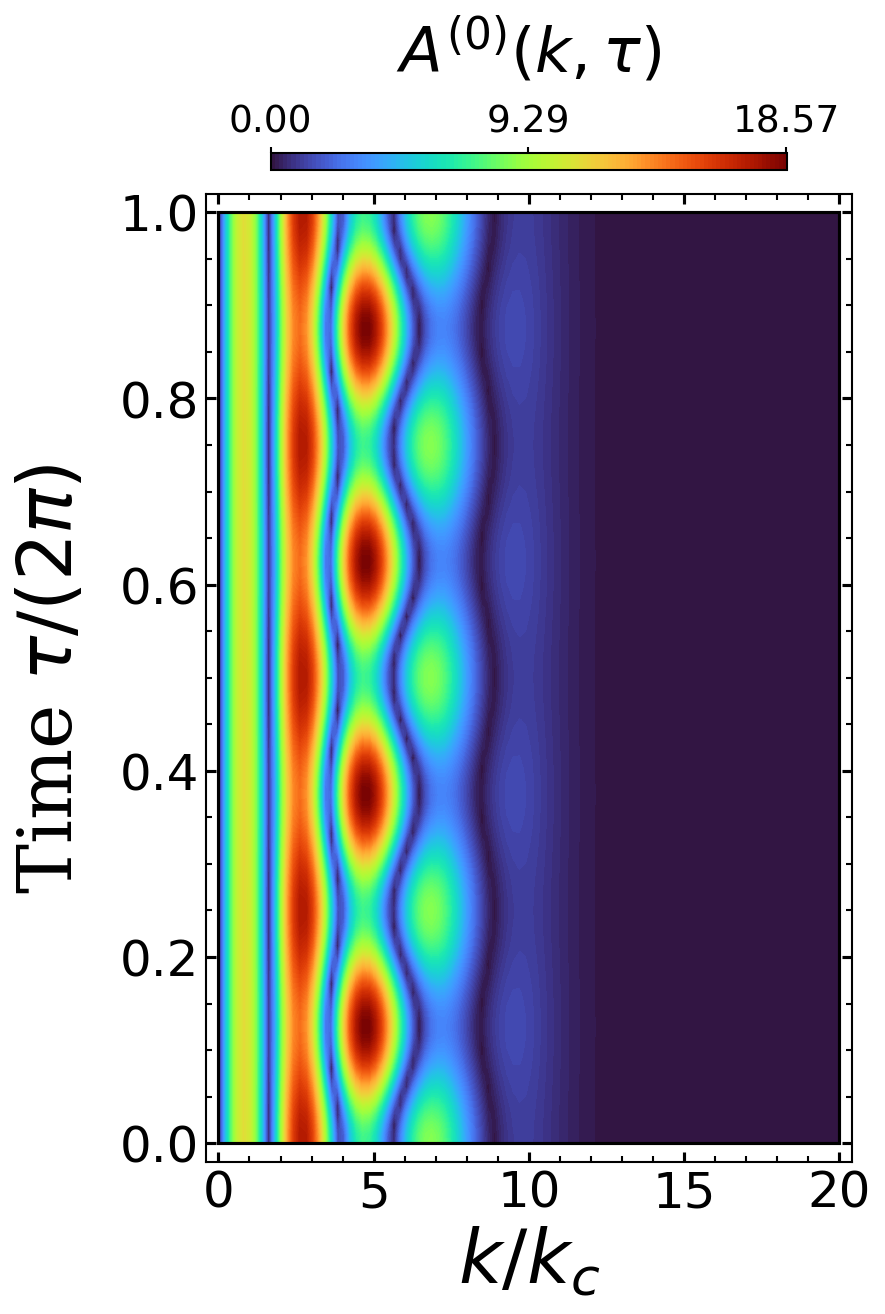

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.ticker import AutoMinorLocator

def plot_density_f_T(kc, Alpha0, Lambda, q, Gamma, f_T):

    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'

    # 1) Set up the grid
    n_k = 100
    n_tau = 100
    k_min, k_max = 0.0, 20.0
    tau_min, tau_max = 0.0, 1.0

    K_vals = np.linspace(k_min, k_max, n_k)
    tau_vals = np.linspace(tau_min, tau_max, n_tau)
    K, T = np.meshgrid(K_vals, tau_vals)

    # 2) Compute the zeroth-order driving amplitude
    Z = np.zeros_like(K, dtype=float)

    for i in range(n_tau):
        for j in range(n_k):
            val = f_T(
                K[i, j] * kc,
                T[i, j] * 2 * np.pi,
                Alpha0, Lambda, q, Gamma
            )
            Z[i, j] = np.abs(K[i, j] * val )

    # 3) Color range
    z_max = np.max(Z)

    cmap = plt.get_cmap('turbo')

    # Initialize the canvas
    fig, ax = plt.subplots(figsize=(6, 9), dpi=150)

    # 4) Draw the contour plot
    cp = ax.contourf(
        K, T, Z,
        levels=150,
        cmap=cmap,
        vmin=0,
        vmax=z_max
    )

    # 5) Frame
    rect = patches.Rectangle(
        (k_min, tau_min),
        k_max - k_min,
        tau_max - tau_min,
        linewidth=1.5,
        edgecolor='black',
        facecolor='none'
    )
    ax.add_patch(rect)

    gap_k = (k_max - k_min) * 0.02
    gap_tau = (tau_max - tau_min) * 0.02

    ax.set_xlim(k_min - gap_k, k_max + gap_k)
    ax.set_ylim(tau_min - gap_tau, tau_max + gap_tau)

    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
        spine.set_linestyle('-')

    # 6) Top colorbar
    cbar = plt.colorbar(
        cp, ax=ax, location='top',
        pad=0.02, shrink=0.8, aspect=30
    )

    cbar.set_ticks([0, z_max / 2, z_max])

    cbar.ax.xaxis.set_ticks_position('top')
    cbar.ax.tick_params(
        labelsize=18, direction='out',
        length=3, width=1
    )
    cbar.outline.set_linewidth(1.0)

    cbar.ax.set_title(
        r'$A^{(0)}(k,\tau)$',
        fontsize=30, fontfamily='serif', pad=15
    )

    # 7) Axis ticks and labels
    ax.set_xticks([0, 5, 10, 15, 20])
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))

    ax.tick_params(
        which='major', direction='in',
        length=5, width=1.5,
        top=True, right=True,
        bottom=True, left=True,
        labelsize=24
    )

    ax.tick_params(
        which='minor', direction='in',
        length=3, width=1.0,
        top=True, right=True,
        bottom=True, left=True
    )

    ax.set_xlabel(r"$k/k_c$", fontsize=36, fontfamily='serif')
    ax.set_ylabel(
        r"Time $\tau/(2\pi)$",
        fontsize=36, fontfamily='serif',
        rotation=90, labelpad=15
    )

    plt.tight_layout()
    plt.show()


plot_density_f_T(kc, Alpha0, Lambda, q, Gamma, f_T)

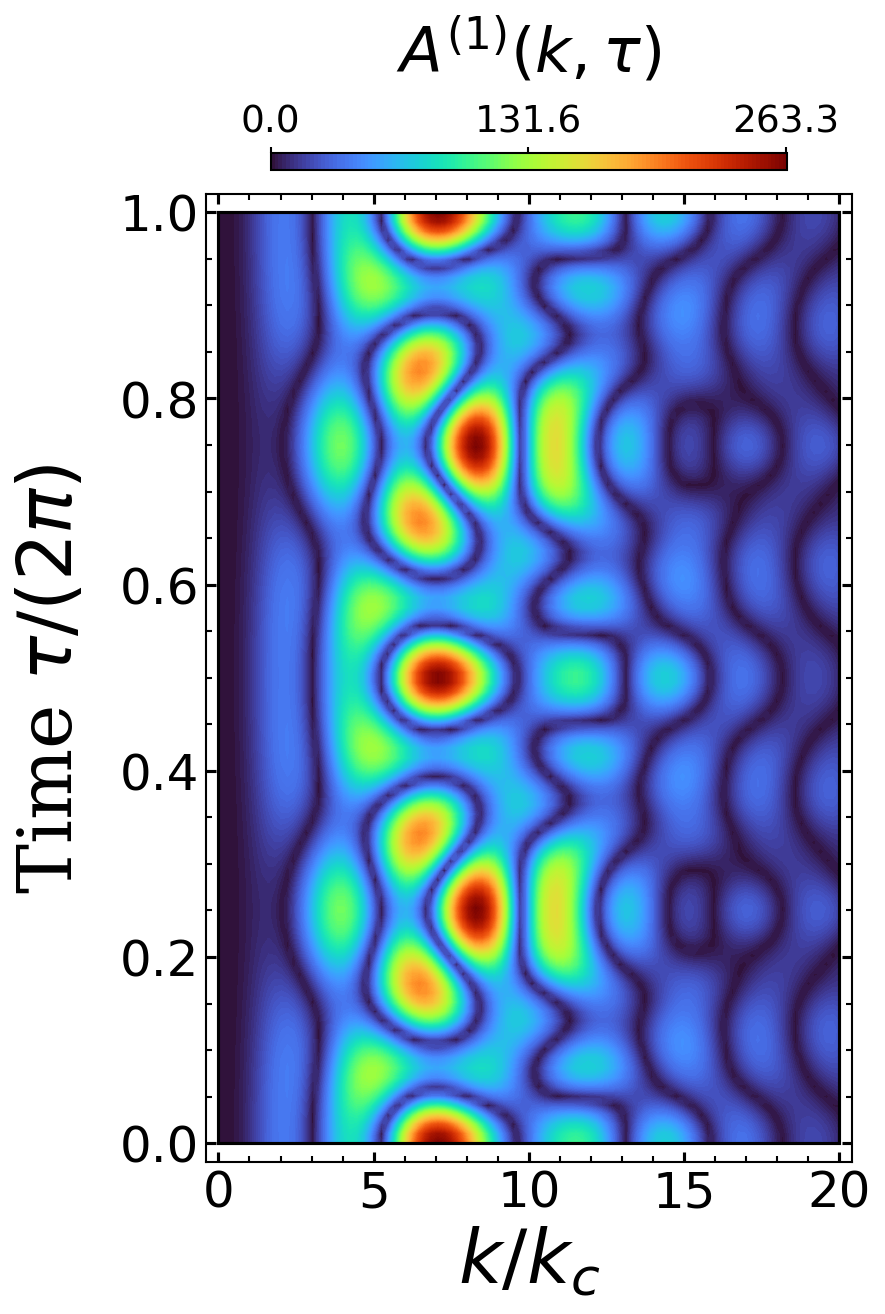

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.ticker import AutoMinorLocator

def plot_density_fHF1(kc, Alpha0, Lambda, q, Gamma, fHF1):

    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'

    # 1) Set up the grid
    n_k = 100
    n_tau = 100
    k_min, k_max = 0.0, 20.0
    tau_min, tau_max = 0.0, 1.0

    K_vals = np.linspace(k_min, k_max, n_k)
    tau_vals = np.linspace(tau_min, tau_max, n_tau)
    K, T = np.meshgrid(K_vals, tau_vals)

    # 2) Compute the first-order driving amplitude
    Z = np.zeros_like(K, dtype=float)

    for i in range(n_tau):
        for j in range(n_k):
            val = fHF1(K[i, j] * kc, T[i, j] * 2 * np.pi)
            Z[i, j] = np.abs(K[i, j] * val )

    # 3) Color range
    z_max = np.max(Z)

    cmap = plt.get_cmap('turbo')

    # Initialize the canvas
    fig, ax = plt.subplots(figsize=(6, 9), dpi=150)

    # 4) Draw the contour plot
    cp = ax.contourf(
        K, T, Z,
        levels=150,
        cmap=cmap,
        vmin=0,
        vmax=z_max
    )

    # 5) Frame
    rect = patches.Rectangle(
        (k_min, tau_min),
        k_max - k_min,
        tau_max - tau_min,
        linewidth=1.5,
        edgecolor='black',
        facecolor='none'
    )
    ax.add_patch(rect)

    gap_k = (k_max - k_min) * 0.02
    gap_tau = (tau_max - tau_min) * 0.02

    ax.set_xlim(k_min - gap_k, k_max + gap_k)
    ax.set_ylim(tau_min - gap_tau, tau_max + gap_tau)

    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
        spine.set_linestyle('-')

    # 6) Top colorbar
    cbar = plt.colorbar(
        cp, ax=ax, location='top',
        pad=0.02, shrink=0.8, aspect=30
    )

    cbar.set_ticks([0, z_max / 2, z_max])

    cbar.ax.xaxis.set_ticks_position('top')
    cbar.ax.tick_params(
        labelsize=18, direction='out',
        length=3, width=1
    )
    cbar.outline.set_linewidth(1.0)

    cbar.ax.set_title(
        r'$A^{(1)}(k,\tau)$',
        fontsize=30, fontfamily='serif', pad=15
    )

    # 7) Axis ticks and labels
    ax.set_xticks([0, 5, 10, 15, 20])
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))

    ax.tick_params(
        which='major', direction='in',
        length=5, width=1.5,
        top=True, right=True,
        bottom=True, left=True,
        labelsize=24
    )

    ax.tick_params(
        which='minor', direction='in',
        length=3, width=1.0,
        top=True, right=True,
        bottom=True, left=True
    )

    ax.set_xlabel(r"$k/k_c$", fontsize=36, fontfamily='serif')
    ax.set_ylabel(
        r"Time $\tau/(2\pi)$",
        fontsize=36, fontfamily='serif',
        rotation=90, labelpad=15
    )

    plt.tight_layout()
    plt.show()


plot_density_fHF1(kc, Alpha0, Lambda, q, Gamma, fHF1)

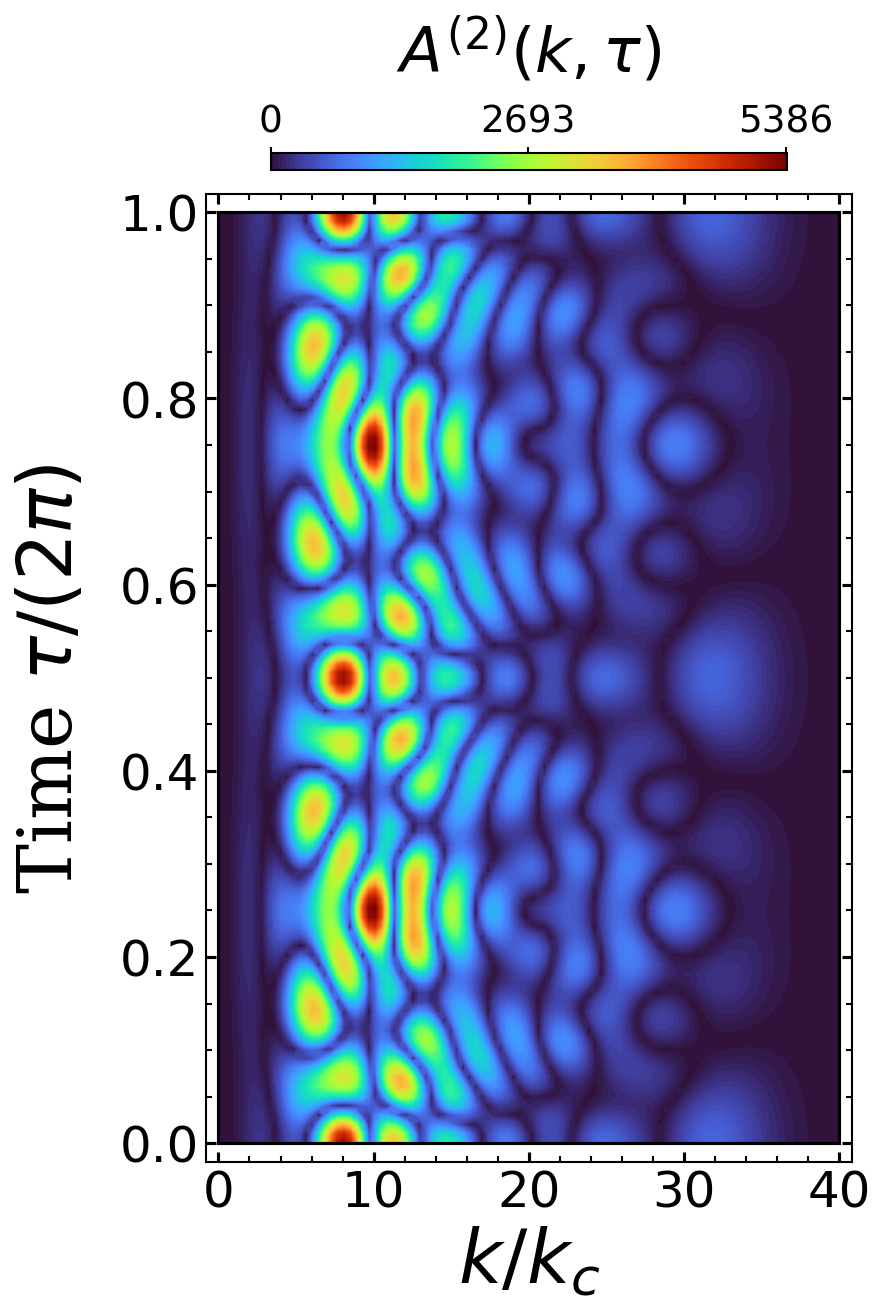

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.ticker import AutoMinorLocator

def plot_density_fHF2(kc, Alpha0, Lambda, q, Gamma, fHF2):

    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'

    # 1) Set up the grid
    n_k = 100
    n_tau = 100
    k_min, k_max = 0.0, 40.0
    tau_min, tau_max = 0.0, 1.0

    K_vals = np.linspace(k_min, k_max, n_k)
    tau_vals = np.linspace(tau_min, tau_max, n_tau)
    K, T = np.meshgrid(K_vals, tau_vals)

    # 2) Compute the second-order driving amplitude
    Z = np.zeros_like(K, dtype=float)

    for i in range(n_tau):
        for j in range(n_k):
            val = fHF2(K[i, j] * kc, T[i, j] * 2 * np.pi)
            Z[i, j] = np.abs(K[i, j] * val )

    # 3) Color range
    z_max = np.max(Z)

    cmap = plt.get_cmap('turbo')

    # Initialize the canvas
    fig, ax = plt.subplots(figsize=(6, 9), dpi=150)

    # 4) Draw the contour plot
    cp = ax.contourf(
        K, T, Z,
        levels=150,
        cmap=cmap,
        vmin=0,
        vmax=z_max
    )

    # 5) Frame
    rect = patches.Rectangle(
        (k_min, tau_min),
        k_max - k_min,
        tau_max - tau_min,
        linewidth=1.5,
        edgecolor='black',
        facecolor='none'
    )
    ax.add_patch(rect)

    gap_k = (k_max - k_min) * 0.02
    gap_tau = (tau_max - tau_min) * 0.02

    ax.set_xlim(k_min - gap_k, k_max + gap_k)
    ax.set_ylim(tau_min - gap_tau, tau_max + gap_tau)

    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
        spine.set_linestyle('-')

    # 6) Top colorbar
    cbar = plt.colorbar(
        cp, ax=ax, location='top',
        pad=0.02, shrink=0.8, aspect=30
    )

    cbar.set_ticks([0, z_max / 2, z_max])

    cbar.ax.xaxis.set_ticks_position('top')
    cbar.ax.tick_params(
        labelsize=18, direction='out',
        length=3, width=1
    )
    cbar.outline.set_linewidth(1.0)

    cbar.ax.set_title(
        r'$A^{(2)}(k,\tau)$',
        fontsize=30, fontfamily='serif', pad=15
    )

    # 7) Axis ticks and labels
    ax.set_xticks([0, 10, 20, 30, 40])
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))

    ax.tick_params(
        which='major', direction='in',
        length=5, width=1.5,
        top=True, right=True,
        bottom=True, left=True,
        labelsize=24
    )

    ax.tick_params(
        which='minor', direction='in',
        length=3, width=1.0,
        top=True, right=True,
        bottom=True, left=True
    )

    ax.set_xlabel(r"$k/k_c$", fontsize=36, fontfamily='serif')
    ax.set_ylabel(
        r"Time $\tau/(2\pi)$",
        fontsize=36, fontfamily='serif',
        rotation=90, labelpad=15
    )

    plt.tight_layout()
    plt.show()


plot_density_fHF2(kc, Alpha0, Lambda, q, Gamma, fHF2)

In [51]:
def plot_density_phase_1(kc, fHF1,
                         ki, kf, tau_i, tau_f, Delta_tau):

    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'

    # 1) Set up the grid
    n_k = 100
    n_tau = 100

    k_min, k_max = ki / kc, kf / kc
    tau_min, tau_max = tau_i / Delta_tau, tau_f / Delta_tau

    K_vals = np.linspace(k_min, k_max, n_k)
    tau_vals = np.linspace(tau_min, tau_max, n_tau)
    K, T = np.meshgrid(K_vals, tau_vals)

    # 2) Compute the first-order phase
    Z = np.zeros_like(K, dtype=float)

    for i in range(n_tau):
        for j in range(n_k):

            k = K[i, j]
            tau = T[i, j]

            val = fHF1(k * kc, tau * Delta_tau)

            z = k * val
            Z[i, j] = np.angle(z) / np.pi if np.abs(z) > 0 else np.nan

    # 3) Plot the phase
    cmap = plt.get_cmap('twilight')

    fig, ax = plt.subplots(figsize=(6, 9), dpi=150)

    cp = ax.pcolormesh(
        K, T, Z,
        cmap=cmap,
        vmin=-1,
        vmax=1,
        shading='auto'
    )   

   
    gap_k = (k_max - k_min) * 0.02
    gap_tau = (tau_max - tau_min) * 0.02

    ax.set_xlim(k_min - gap_k, k_max + gap_k)
    ax.set_ylim(tau_min - gap_tau, tau_max + gap_tau)

    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
        spine.set_linestyle('-')

    # 5) Top colorbar
    cbar = plt.colorbar(
        cp, ax=ax, location='top',
        pad=0.02, shrink=0.8, aspect=30
    )

    cbar.set_ticks([-1, 0, 1])
    cbar.ax.set_xticklabels([r'$-1$', r'$0$', r'$1$'])

    cbar.ax.xaxis.set_ticks_position('top')
    cbar.ax.tick_params(
        labelsize=18, direction='out',
        length=3, width=1
    )
    cbar.outline.set_linewidth(1.0)

    cbar.ax.set_title(
        r'$\phi^{(1)}(k,\tau)/\pi$',
        fontsize=30, fontfamily='serif', pad=15
    )

    # 6) Axis ticks and labels
    ax.set_xticks(np.linspace(k_min, k_max, 5))
    ax.set_yticks(np.linspace(tau_min, tau_max, 6))

    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))

    ax.tick_params(
        which='major', direction='in',
        length=5, width=1.5,
        top=True, right=True,
        bottom=True, left=True,
        labelsize=24
    )

    ax.tick_params(
        which='minor', direction='in',
        length=3, width=1.0,
        top=True, right=True,
        bottom=True, left=True
    )

    ax.set_xlabel(r"$k/k_c$", fontsize=36, fontfamily='serif')
    ax.set_ylabel(
        r"Time $\tau/\Delta\tau$",
        fontsize=36, fontfamily='serif',
        rotation=90, labelpad=15
    )

    plt.tight_layout()
    plt.show()

In [54]:
def plot_density_phase_2(kc, fHF2,
                         ki, kf, tau_i, tau_f, Delta_tau):

    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'

    # 1) Set up the grid
    n_k = 100
    n_tau = 100

    k_min, k_max = ki / kc, kf / kc
    tau_min, tau_max = tau_i / Delta_tau, tau_f / Delta_tau

    K_vals = np.linspace(k_min, k_max, n_k)
    tau_vals = np.linspace(tau_min, tau_max, n_tau)
    K, T = np.meshgrid(K_vals, tau_vals)

    # 2) Compute the second-order phase
    Z = np.zeros_like(K, dtype=float)

    for i in range(n_tau):
        for j in range(n_k):

            k = K[i, j]
            tau = T[i, j]

            val = fHF2(k * kc, tau * Delta_tau)

            z = k * val
            Z[i, j] = np.angle(z) / np.pi if np.abs(z) > 0 else np.nan

    # 3) Plot the phase
    cmap = plt.get_cmap('twilight')

    fig, ax = plt.subplots(figsize=(6, 9), dpi=150)

    cp = ax.pcolormesh(
        K, T, Z,
        cmap=cmap,
        vmin=-1,
        vmax=1,
        shading='auto'
    )
    gap_k = (k_max - k_min) * 0.02
    gap_tau = (tau_max - tau_min) * 0.02

    ax.set_xlim(k_min - gap_k, k_max + gap_k)
    ax.set_ylim(tau_min - gap_tau, tau_max + gap_tau)

    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
        spine.set_linestyle('-')

    # 5) Top colorbar
    cbar = plt.colorbar(
        cp, ax=ax, location='top',
        pad=0.02, shrink=0.8, aspect=30
    )

    cbar.set_ticks([-1, 0, 1])
    cbar.ax.set_xticklabels([r'$-1$', r'$0$', r'$1$'])

    cbar.ax.xaxis.set_ticks_position('top')
    cbar.ax.tick_params(
        labelsize=18, direction='out',
        length=3, width=1
    )
    cbar.outline.set_linewidth(1.0)

    cbar.ax.set_title(
        r'$\phi^{(2)}(k,\tau)/\pi$',
        fontsize=30, fontfamily='serif', pad=15
    )

    # 6) Axis ticks and labels
    ax.set_xticks(np.linspace(k_min, k_max, 5))
    ax.set_yticks(np.linspace(tau_min, tau_max, 6))

    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))

    ax.tick_params(
        which='major', direction='in',
        length=5, width=1.5,
        top=True, right=True,
        bottom=True, left=True,
        labelsize=24
    )

    ax.tick_params(
        which='minor', direction='in',
        length=3, width=1.0,
        top=True, right=True,
        bottom=True, left=True
    )

    ax.set_xlabel(r"$k/k_c$", fontsize=36, fontfamily='serif')
    ax.set_ylabel(
        r"Time $\tau/\Delta\tau$",
        fontsize=36, fontfamily='serif',
        rotation=90, labelpad=15
    )

    plt.tight_layout()
    plt.show()

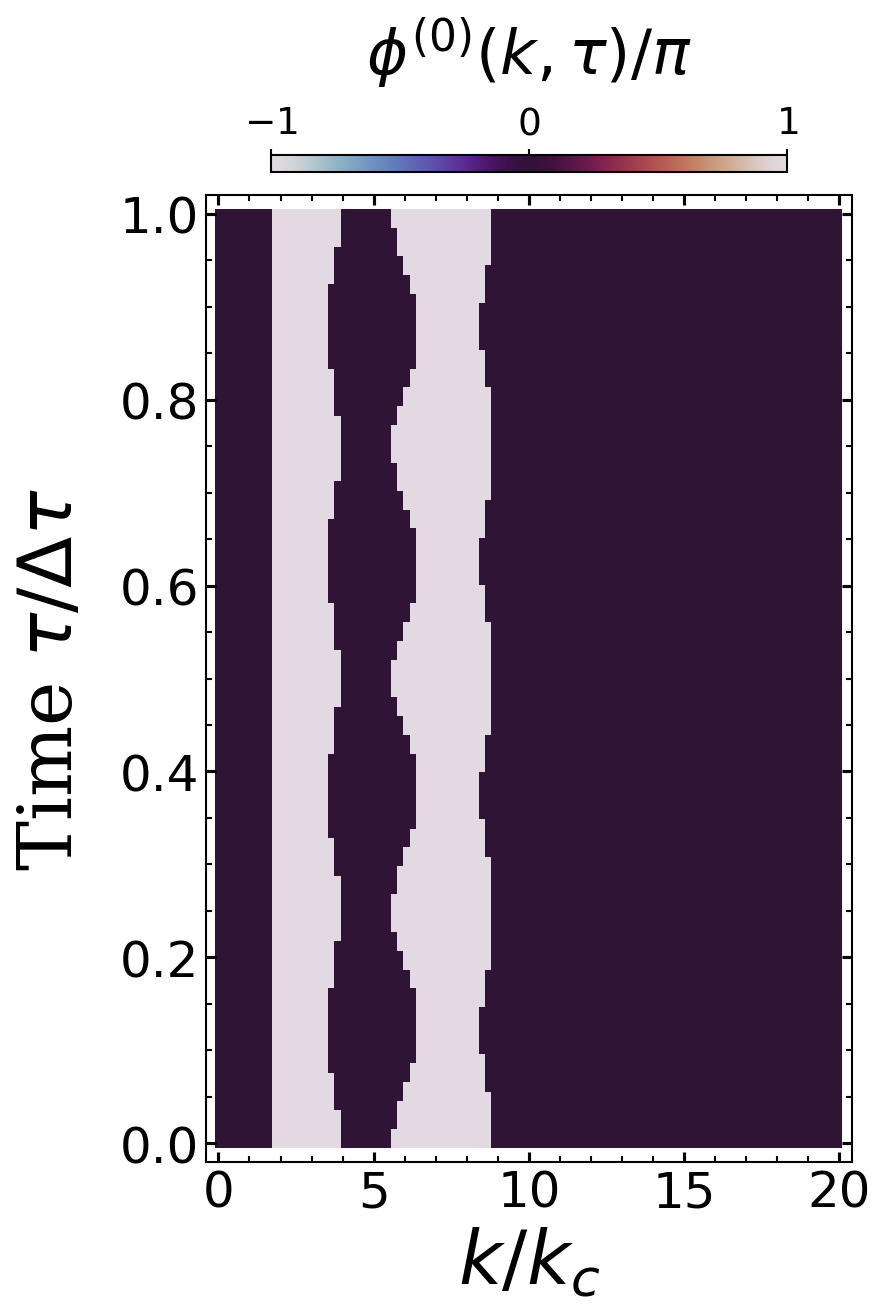

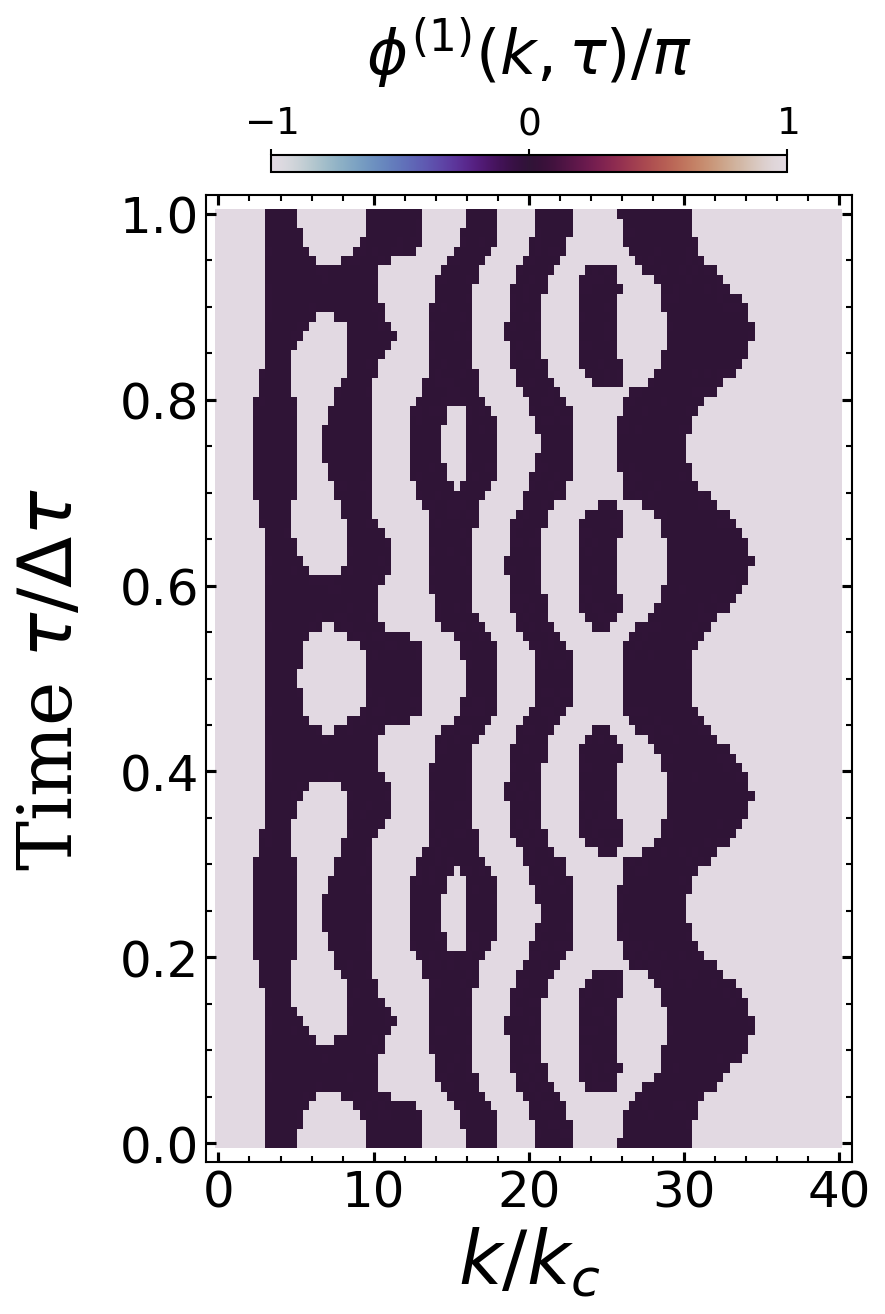

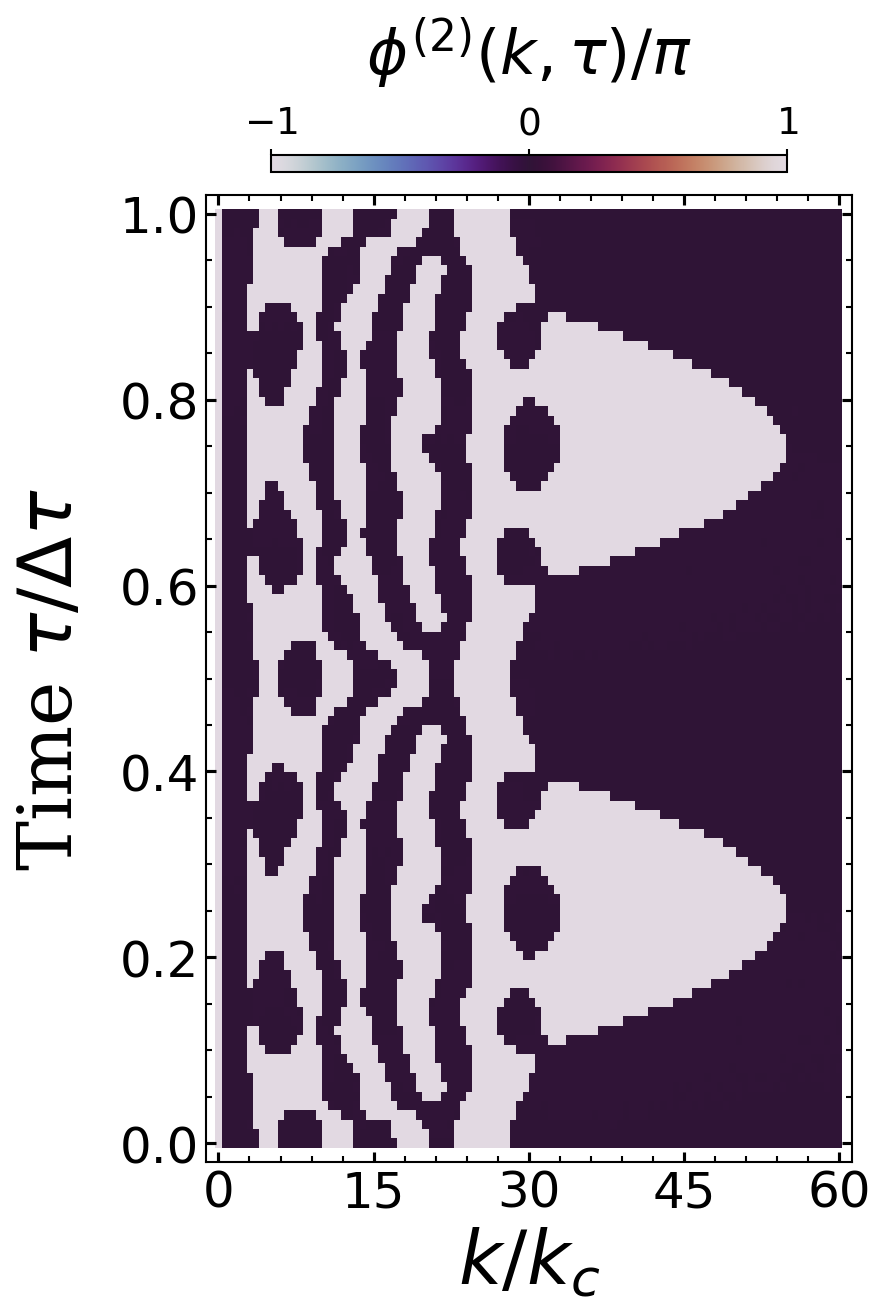

In [55]:
# Zeroth order: set kf independently
plot_density_phase_0(
    kc, Alpha0, Lambda, q, Gamma,
    f_T, ki, 20 * kc, tau_i, tau_f, Delta_tau
)

# First order: set kf independently
plot_density_phase_1(
    kc, fHF1,
    ki, 40 * kc, tau_i, tau_f, Delta_tau
)

# Second order: set kf independently
plot_density_phase_2(
    kc, fHF2,
    ki, 60 * kc, tau_i, tau_f, Delta_tau
)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

def plot_density_fHF2(kc, Alpha0, Lambda, q, Gamma, fHF2):

    # 1) Set up the grid
    n_k = 100
    n_tau = 100
    K_vals = np.linspace(0.0, 65*kc, n_k)
    tau_vals = np.linspace(0.0, 2, n_tau)
    K, T = np.meshgrid(K_vals, tau_vals)  # Build the mesh

    # 2) Compute Z
    Z = np.zeros_like(K, dtype=float)
    for i in range(n_tau):
        for j in range(n_k):
            val = fHF2(K[i, j] * kc, T[i, j] * 2 * np.pi)
            Z[i, j] = np.abs(K[i, j] * val)

    # 3) Smart extraction of the data range (eliminates the destructive compression of colors by extreme peaks)
    # Take the 98th percentile as the maximum so that the vast majority of details are distributed across different color bands
    z_max = np.percentile(Z, 98)
    z_min = 0.0

    # 4) Use the 'turbo' colormap, which is extremely vivid and strongly layered
    # If you prefer the classic red-yellow-blue transition, you can also use 'RdYlBu_r' or 'jet'
    cmap = plt.get_cmap('turbo')

    # 5) Plot the density map
    fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

    # Increase levels to 150; together with the turbo colormap this produces silky-smooth, sharply layered contours
    cp = ax.contourf(K, T, Z, levels=150, cmap=cmap, vmin=z_min, vmax=z_max)

    # 6) Add a colorbar
    cbar = plt.colorbar(cp, ax=ax, pad=0.05, shrink=1, orientation='vertical')
    cbar.ax.tick_params(labelsize=20, direction='in', length=8, width=2)
    cbar.outline.set_linewidth(2.5)


    # cbar.locator = plt.MaxNLocator(5)
    # cbar.update_ticks()

    # 7) Frame labels
    ax.set_xlabel("k/kc", fontsize=30, fontweight='bold')
    ax.set_ylabel("τ/2π", fontsize=30, fontweight='bold', rotation=0, labelpad=20)

    # 8) Frame style: set all spines to black with linewidth 3
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(3)

    plt.tight_layout()
    plt.show()

# Example call
plot_density_fHF2(kc, Alpha0, Lambda, q, Gamma, fHF2)

In [ ]:

#Discretize the chart of NcTF coefficient
def Mf2():
    Mf2 = []
    for k in k_array_global:
        row = [fHF2(k, tau) for tau in t_values_global]
        Mf2.append(row)
    return np.array(Mf2)
Mf2 = Mf2()
Mf2[71]

In [ ]:
MfT2 = beta_d * MfT - (beta_d**2) * Mf1 -(beta_d**3) * Mf2
print(MfT2)

In [ ]:
MfT1 = beta_d * MfT - (beta_d**2 ) * Mf1
print(MfT1)

In [ ]:
#Redefine the NcFT coefficients with discretised data .
def fT2(i_k, tau, Alpha0, Lambda, q, Gamma, MfT2): # Fix: add the missing MfT2 parameter
    # Subtract 0.5 * d_tau to align exactly with the midpoint grid
    i_tau = int(round((tau - tau_i - 0.5 * d_tau) / d_tau)) % MfT2.shape[1]
    return MfT2[i_k, i_tau]

def HT2(n, m, tau, MfT2, Lambda, q, Gamma):
    total = 0.0
    if m >= n:
        T0 = np.sqrt(factorial(n - 1) / factorial(m - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda / 4) * k**2 - 1j * (m - n) * tau)
            T2 = genlaguerre(n - 1, m - n)((Lambda / 2) * k**2)
            T3 = fT2(idx, tau, Alpha0, Lambda, q, Gamma, MfT2) # Fix: pass in MfT2
            T4 = (np.sqrt(Lambda / 2) * 1j * k)**(m - n)
            total += weight * (k * T1 * T2 * np.real(T3 * T4) * T0)
        return total
    else:
        T0 = np.sqrt(factorial(m - 1) / factorial(n - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda / 4) * k**2 - 1j * (m - n) * tau)
            T2 = genlaguerre(m - 1, n - m)((Lambda / 2) * k**2)
            T3 = fT2(idx, tau, Alpha0, Lambda, q, Gamma, MfT2) # Fix: pass in MfT2
            T4 = (np.sqrt(Lambda / 2) * 1j * k)**(n - m)
            total += weight * (k * T1 * T2 * np.real(T3 * T4) * T0)
        return total


In [ ]:
# Compute the current driving amplitude 
beta_i = 1e-3    # Initial driving amplitude
beta_f = 1.0     # Final driving amplitude
N_beta = 15      # Total number of driving points
N_beta_i = 0    # Starting point index
N_beta_f = 15    # Ending point index

In [ ]:
# ==========================================
# Zeroth- and first-order (FM) calculation section 
# ==========================================
def fT1(i_k, tau, Alpha0, Lambda, q, Gamma, MfT1):
    # Fix: likewise, subtract 0.5 * d_tau to align exactly with the midpoint grid!
    i_tau = int(round((tau - tau_i - 0.5 * d_tau) / d_tau)) % MfT1.shape[1]
    return MfT1[i_k, i_tau]

def HT1(n, m, tau, MfT1):
    total = 0.0
    if m >= n:
        T0 = np.sqrt(factorial(n - 1) / factorial(m - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda/4)*k**2 - 1j*(m - n)*tau)
            T2 = genlaguerre(n - 1, m - n)((Lambda / 2) * k**2)
            T3 = fT1(idx, tau, Alpha0, Lambda, q, Gamma, MfT1) # Pass in MfT1
            T4 = (np.sqrt(Lambda/2) * 1j * k)**(m - n)
            total += weight * (k * T1 * T2 * np.real(T3*T4) * T0)
        return total
    else:
        T0 = np.sqrt(factorial(m - 1) / factorial(n - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda/4)*k**2 - 1j*(m - n)*tau)
            T2 = genlaguerre(m - 1, n - m)((Lambda / 2) * k**2)
            T3 = fT1(idx, tau, Alpha0, Lambda, q, Gamma, MfT1) # Pass in MfT1
            T4 = (np.sqrt(Lambda/2) * 1j * k)**(n - m)
            total += weight * (k * T1 * T2 * np.real(T3*T4) * T0)
        return total

def U(tau, beta_d):
    Htau = np.zeros((Np, Np), dtype=np.complex128)
    for n in range(Np):
        for m in range(Np):
            Htau[n, m] = beta_d * H(n+1, m+1, tau)
    return expm(-(1j / Lambda) * Htau * d_tau)

def U1(tau, MfT1):
    Htau = np.zeros((Np, Np), dtype=np.complex128)
    for n in range(Np):
        for m in range(Np):
            Htau[n, m] = HT1(n+1, m+1, tau, MfT1) # Pass in MfT1
    return expm(-(1j/Lambda) * Htau * d_tau)

FM = []
for ii in tqdm(range(N_beta_i, N_beta_f + 1), desc="Processing β (0th & 1st Order)"):
    beta_d = beta_i * (beta_f / beta_i) ** (ii / N_beta)

    num_steps = int(round(Delta_tau / d_tau))
    # Fix: must use midpoint times instead, to avoid O(dt) errors destroying the high-order slope!
    taus = [tau_i + (j - 0.5) * d_tau for j in range(1, num_steps + 1)]
    taus_rev = taus[::-1]

    # === 0th-order evolution ===
    UFtemp_rev = Parallel(n_jobs=-1)(delayed(U)(tau, beta_d) for tau in taus_rev)
    FU = np.eye(Np, dtype=np.complex128)
    for M_mat in UFtemp_rev:
        FU = np.dot(FU, M_mat)

    # === 1st-order evolution ===
    MfT1 = beta_d * MfT - (beta_d**2) * Mf1
    UFtemp1_rev = Parallel(n_jobs=-1)(delayed(U1)(tau, MfT1) for tau in taus_rev)
    FU1 = np.eye(Np, dtype=np.complex128)
    for M_mat in UFtemp1_rev:
        FU1 = np.dot(FU1, M_mat)

    # === Compute the fidelity ===
    FMFU0 = Psi_codel.conj().T @ (FU @ Psi_codel)
    FMFU1 = Psi_codel.conj().T @ (FU1 @ Psi_codel)

    FM.append([beta_d * 1.0, FMFU0, FMFU1])

print(FM)

In [ ]:
import numpy as np
import scipy.io as sio

# ==========================================
# Separately export the 0th- and 1st-order fidelity evolution data (FM)
# ==========================================
# Convert the list to a NumPy array of objects
FM_array = np.array(FM, dtype=object)

# Option 1: Save in Python's native format
np.save("FM_data.npy", FM_array, allow_pickle=True)
print("FM data successfully saved separately as FM_data.npy")

In [ ]:
# ==========================================
# Second-order (FM2) calculation section 
# ==========================================
def fT2(i_k, tau, Alpha0, Lambda, q, Gamma, MfT2): # Fix: add the missing MfT2 parameter
    # Subtract 0.5 * d_tau to align exactly with the midpoint grid
    i_tau = int(round((tau - tau_i - 0.5 * d_tau) / d_tau)) % MfT2.shape[1]
    return MfT2[i_k, i_tau]

def HT2(n, m, tau, MfT2, Lambda, q, Gamma):
    total = 0.0
    if m >= n:
        T0 = np.sqrt(factorial(n - 1) / factorial(m - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda / 4) * k**2 - 1j * (m - n) * tau)
            T2 = genlaguerre(n - 1, m - n)((Lambda / 2) * k**2)
            T3 = fT2(idx, tau, Alpha0, Lambda, q, Gamma, MfT2) # Fix: pass in MfT2
            T4 = (np.sqrt(Lambda / 2) * 1j * k)**(m - n)
            total += weight * (k * T1 * T2 * np.real(T3 * T4) * T0)
        return total
    else:
        T0 = np.sqrt(factorial(m - 1) / factorial(n - 1))
        for idx, k in enumerate(k_array_global):
            weight = simpson_weights[idx]
            T1 = np.exp(-(Lambda / 4) * k**2 - 1j * (m - n) * tau)
            T2 = genlaguerre(m - 1, n - m)((Lambda / 2) * k**2)
            T3 = fT2(idx, tau, Alpha0, Lambda, q, Gamma, MfT2) # Fix: pass in MfT2
            T4 = (np.sqrt(Lambda / 2) * 1j * k)**(n - m)
            total += weight * (k * T1 * T2 * np.real(T3 * T4) * T0)
        return total

def U2(tau, MfT2, Lambda, Alpha0, q, Gamma, beta_d):
    Htau = np.zeros((Np, Np), dtype=np.complex128)
    for n in range(Np):
        for m in range(Np):
            Htau[n, m] = HT2(n + 1, m + 1, tau, MfT2, Lambda, q, Gamma)
    return expm(-(1j / Lambda) * Htau * d_tau)

def U2F(t0, Delta_tau, d_tau, MfT2, Lambda, Alpha0, q, Gamma, beta_d):
    num_steps = int(round(Delta_tau / d_tau))
    # Fix: must use the midpoint time sequence! (j - 0.5)
    taus = [t0 + (j - 0.5) * d_tau for j in range(1, num_steps + 1)]
    taus_rev = taus[::-1]

    # Pass the parameters explicitly
    UFtemp_rev = Parallel(n_jobs=-1)(delayed(U2)(tau, MfT2, Lambda, Alpha0, q, Gamma, beta_d) for tau in taus_rev)
    result = np.eye(Np, dtype=np.complex128)
    for M in UFtemp_rev:
        result = np.dot(result, M)
    return result

FM2 = []
for ii in tqdm(range(N_beta_i, N_beta_f + 1), desc="Processing β (2nd Order)"):
    beta_d = beta_i * (beta_f / beta_i) ** (ii / N_beta)
    MfT2 = beta_d * MfT - (beta_d**2) * Mf1 - (beta_d**3) * Mf2
    FU2 = U2F(tau_i, Delta_tau, d_tau, MfT2, Lambda, Alpha0, q, Gamma, beta_d)
    FMFU2 = Psi_codel.conj().T @ (FU2 @ Psi_codel)
    FM1 = [beta_d * 1.0, FMFU2]
    FM2.append(FM1)
print(FM2)

In [ ]:
import numpy as np
import scipy.io as sio

# ==========================================
# Export the 2nd-order fidelity evolution data (FM2)
# ==========================================
# Convert the list to a NumPy array of objects
FM2_array = np.array(FM2, dtype=object)

# Option 1: Save in Python's native format
np.save("FM2_data.npy", FM2_array, allow_pickle=True)
print("FM2 data successfully saved separately as FM2_data.npy")


In [ ]:
import numpy as np

# allow_pickle=True is required when loading
FM = np.load("FM_data.npy", allow_pickle=True).tolist()
FM2= np.load("FM2_data.npy", allow_pickle=True).tolist()

print("Data loaded successfully! Number of points in FM:", len(FM_loaded))

In [ ]:
F1 = []
for item in FM:
    # Each item is a list: item[0] is a scalar, item[1] is the first matrix
    mat = item[1]
    # Take the modulus of each matrix element
    F1.append(np.abs(mat))
F1

In [ ]:
F2 = []
for item in FM:
    # Each item is a list: item[0] is a scalar, item[1] is the first matrix
    mat = item[2]
    # Take the modulus of each matrix element
    F2.append(np.abs(mat))
F2

In [ ]:
F3 = []
for item in FM2:
    # Each item is a list: item[0] is a scalar, item[1] is the first matrix
    mat = item[1]
    # Take the modulus of each matrix element
    F3.append(np.abs(mat))
F3


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

p1_curves = []
p2_curves = []
p3_curves = []

# Iterate directly over the length of the actually computed data
for i in range(len(FM)):
    # Extract the true beta_d directly from your data list as the X axis
    true_beta = FM[i][0]

    # Compute the averages
    y_avg_f1 = np.mean([1 - F1[i][n-1][n-1] for n in range(1, 5)])
    y_avg_f2 = np.mean([1 - F2[i][n-1][n-1] for n in range(1, 5)])
    # Note: make sure the length of the F3 list matches F1/F2; using FM2 for the true beta here also works
    y_avg_f3 = np.mean([1 - F3[i][n-1][n-1] for n in range(1, 5)])

    p1_curves.append((true_beta, y_avg_f1))
    p2_curves.append((true_beta, y_avg_f2))
    p3_curves.append((true_beta, y_avg_f3))

# ================= Plotting section =================
fig, ax = plt.subplots(figsize=(8,8))

for x_val, y_avg in p1_curves:
    ax.loglog(x_val, y_avg, color='gray', marker='o', linestyle='', markersize=10)

for x_val, y_avg in p2_curves:
    ax.loglog(x_val, y_avg, color='red', marker='o', linestyle='', markersize=10)

for x_val, y_avg in p3_curves:
    ax.loglog(x_val, y_avg, color='blue', marker='o', linestyle='', markersize=10)

legend_elements = [
    Line2D([0], [0], marker='o', color='white', linestyle='', label='F1 (0th Order)'),
    Line2D([0], [0], marker='o', color='red', linestyle='', label='F2 (1st Order)'),
    Line2D([0], [0], marker='o', color='blue', linestyle='', label='F3 (2nd Order)')
]

ax.set_aspect(1/4)
ax.tick_params(labelsize=20)
ax.grid(True, which="both", ls="--", alpha=0.3)
ax.set_xlabel('Driving amplitude $\\beta$', fontsize=30, fontweight='bold')
ax.set_ylabel('Infidelity', fontsize=30, fontweight='bold')
ax.legend(handles=legend_elements, fontsize=15)

# If the background feels too dark, you can add this line, or keep your default dark mode
# fig.patch.set_facecolor('#212121')
# ax.set_facecolor('#212121')

fig.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ================= 1. Faithfully replicate Mathematica's slope extraction =================
print("Extract the scaling exponents from 4 code states for the zeroth order correction:")
# Find the Python index closest to Mathematica's beta=0.020
# In Python, N_beta=15, range 1e-3 to 1.0, so at ii=7, beta = 10^(-3 + 3*7/15) = 10^(-1.6) ≈ 0.025
idx_1 = 0  # Corresponds to beta = 0.001
idx_5 = 7  # Approximately corresponds to Mathematica's beta = 0.020

beta_1 = FM[idx_1][0]
beta_5 = FM[idx_5][0]

slopes_F1 = [(np.log(1 - F1[idx_5][i][i].real) - np.log(1 - F1[idx_1][i][i].real)) / (np.log(beta_5) - np.log(beta_1)) for i in range(4)]
print(slopes_F1)

print("Extract the scaling exponents from 4 code states for the first order correction:")
slopes_F2 = [(np.log(1 - F2[idx_5][i][i].real) - np.log(1 - F2[idx_1][i][i].real)) / (np.log(beta_5) - np.log(beta_1)) for i in range(4)]
print(slopes_F2)

print("Extract the scaling exponents from 4 code states for the second order correction:")
slopes_F3 = [(np.log(1 - F3[idx_5][i][i].real) - np.log(1 - F3[idx_1][i][i].real)) / (np.log(beta_5) - np.log(beta_1)) for i in range(4)]
print(slopes_F3)

# ================= 2. Prepare the corrected plotting data =================
p1_curves = []
p2_curves = []
p3_curves = []

for i in range(len(FM)):
    true_beta = FM[i][0]

    # 🚨 Fix: must use range(4) to include all 4 states!
    y_avg_f1 = np.mean([1 - F1[i][n][n].real for n in range(4)])
    y_avg_f2 = np.mean([1 - F2[i][n][n].real for n in range(4)])
    y_avg_f3 = np.mean([1 - F3[i][n][n].real for n in range(4)])

    p1_curves.append((true_beta, y_avg_f1))
    p2_curves.append((true_beta, y_avg_f2))
    p3_curves.append((true_beta, y_avg_f3))

x_vals = np.array([pt[0] for pt in p1_curves])
y_f1 = np.array([pt[1] for pt in p1_curves])
y_f2 = np.array([pt[1] for pt in p2_curves])
y_f3 = np.array([pt[1] for pt in p3_curves])

# ================= 3. Strictly restricted plotting and fitting =================
fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

ax.loglog(x_vals, y_f1, color='gray', marker='o', linestyle='', markersize=10)
ax.loglog(x_vals, y_f2, color='red', marker='o', linestyle='', markersize=10)
ax.loglog(x_vals, y_f3, color='blue', marker='o', linestyle='', markersize=10)

def plot_real_fit_line(ax, x, y, color, offset_factor=0.2):
    # 🚨 Fix: fit only up to the region around beta ≈ 0.025 (idx=7), strictly matching Mathematica's range
    # Never use 10, otherwise the saturated, bent points on the right would be pulled into the fit, making the slope artificially steep!
    fit_start = 0
    fit_end = 7

    x_fit = x[fit_start:fit_end]
    y_fit = y[fit_start:fit_end]

    log_x = np.log10(x_fit)
    log_y = np.log10(y_fit)

    coeffs = np.polyfit(log_x, log_y, 1)
    real_slope = coeffs[0]
    intercept = coeffs[1]

    print(f"[{color} line fit] Using the first {fit_end} points, slope: {real_slope:.4f}")

    ref_x = x[0:8]
    ref_y = (10**intercept) * (ref_x ** real_slope) * offset_factor
    ax.loglog(ref_x, ref_y, color=color, linestyle='--', linewidth=2.5, alpha=0.8)

    text_x = ref_x[2]
    text_y = ref_y[2] * 0.25
    ax.text(text_x, text_y, f'$\\propto \\beta^{{{real_slope:.2f}}}$',
            color=color, fontsize=20, fontweight='bold')

# Call the new function with the restricted fit range
plot_real_fit_line(ax, x_vals, y_f1, 'gray', offset_factor=0.15)
plot_real_fit_line(ax, x_vals, y_f2, 'red',  offset_factor=0.1)
plot_real_fit_line(ax, x_vals, y_f3, 'blue', offset_factor=0.03)

# Formatting
legend_elements = [
    Line2D([0], [0], marker='o', color='gray', linestyle='', label='F1 (0th Order)'),
    Line2D([0], [0], marker='o', color='red', linestyle='', label='F2 (1st Order)'),
    Line2D([0], [0], marker='o', color='blue', linestyle='', label='F3 (2nd Order)')
]

ax.set_aspect('auto')
ax.tick_params(labelsize=22, direction='in', length=8, width=2)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(2.5)

ax.grid(True, which="both", ls="--", alpha=0.3)
ax.set_xlabel('Driving amplitude $\\beta$', fontsize=30, fontweight='bold')
ax.set_ylabel('Infidelity', fontsize=30, fontweight='bold')
ax.legend(handles=legend_elements, fontsize=18, loc='lower right')

fig.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Physical parameter definitions
beta_i = 1e-3    # Initial driving amplitude (0.001)
beta_f = 1.0     # Final driving amplitude (1.0)
N_beta = 15      # Total number of driving points (number of intervals)
N_beta_i = 0     # Starting point index
N_beta_f = 15    # Ending point index

# Separately extract and compute the list of beta_d values in the FM loop
beta_values = []
for ii in range(N_beta_i, N_beta_f + 1):
    beta_d = beta_i * (beta_f / beta_i) ** (ii / N_beta)
    beta_values.append(beta_d)

# Print the results for inspection
print(f"Generated {len(beta_values)} beta_d points in total:")
for i, b in enumerate(beta_values):
    print(f"ii = {i:2d}  |  beta_d = {b:.8f}  (approx. {b:.2e})")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ================= 0. Regenerate the x-axis beta_values =================
# Precisely reconstruct the 16 beta points using the previous exponential interpolation formula
beta_i = 1e-3
beta_f = 1.0
N_beta = 15
beta_values = [beta_i * (beta_f / beta_i) ** (ii / N_beta) for ii in range(N_beta + 1)]


# ================= 1. Faithfully replicate Mathematica's slope extraction =================
print("Extract the scaling exponents from 4 code states for the zeroth order correction:")
idx_1 = 0  # Corresponds to beta = 0.001
idx_5 = 7  # Approximately corresponds to Mathematica's beta ≈ 0.025

beta_1 = beta_values[idx_1]
beta_5 = beta_values[idx_5]

slopes_F1 = [(np.log(1 - F1[idx_5][i][i].real) - np.log(1 - F1[idx_1][i][i].real)) / (np.log(beta_5) - np.log(beta_1)) for i in range(4)]
print("0th Order slopes:", slopes_F1)

print("Extract the scaling exponents from 4 code states for the first order correction:")
slopes_F2 = [(np.log(1 - F2[idx_5][i][i].real) - np.log(1 - F2[idx_1][i][i].real)) / (np.log(beta_5) - np.log(beta_1)) for i in range(4)]
print("1st Order slopes:", slopes_F2)

print("Extract the scaling exponents from 4 code states for the second order correction:")
slopes_F3 = [(np.log(1 - F3[idx_5][i][i].real) - np.log(1 - F3[idx_1][i][i].real)) / (np.log(beta_5) - np.log(beta_1)) for i in range(4)]
print("2nd Order slopes:", slopes_F3)


# ================= 2. Prepare the corrected plotting data =================
x_vals = []
y_f1 = []
y_f2 = []
y_f3 = []

# Iterate directly over the length of beta_values (16 points)
for i in range(len(beta_values)):
    true_beta = beta_values[i]

    # Take the diagonal elements of the 4 states (n=0,1,2,3), compute the infidelity, and average
    y_avg_f1 = np.mean([1 - F1[i][n][n].real for n in range(4)])
    y_avg_f2 = np.mean([1 - F2[i][n][n].real for n in range(4)])
    y_avg_f3 = np.mean([1 - F3[i][n][n].real for n in range(4)])

    x_vals.append(true_beta)
    y_f1.append(y_avg_f1)
    y_f2.append(y_avg_f2)
    y_f3.append(y_avg_f3)

x_vals = np.array(x_vals)
y_f1 = np.array(y_f1)
y_f2 = np.array(y_f2)
y_f3 = np.array(y_f3)


# ================= 3. Strictly restricted plotting and fitting =================
fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

# Plot the scatter points
ax.loglog(x_vals, y_f1, color='gray', marker='o', linestyle='', markersize=10)
ax.loglog(x_vals, y_f2, color='red', marker='o', linestyle='', markersize=10)
ax.loglog(x_vals, y_f3, color='blue', marker='o', linestyle='', markersize=10)

def plot_real_fit_line(ax, x, y, color, offset_factor=0.2):
    # Fit only the purely perturbative region up to beta ≈ 0.025 (idx=7), preventing high-order saturation from bending the slope
    fit_start = 0
    fit_end = 6

    x_fit = x[fit_start:fit_end]
    y_fit = y[fit_start:fit_end]

    log_x = np.log10(x_fit)
    log_y = np.log10(y_fit)

    # Linear fit to extract the power-law exponent
    coeffs = np.polyfit(log_x, log_y, 1)
    real_slope = coeffs[0]
    intercept = coeffs[1]

    print(f"[{color} line fit] Using the first {fit_end} points, empirical slope: {real_slope:.4f}")

    # Draw the auxiliary extension line
    ref_x = x[0:8]
    ref_y = (10**intercept) * (ref_x ** real_slope) * offset_factor
    ax.loglog(ref_x, ref_y, color=color, linestyle='--', linewidth=2.5, alpha=0.8)

    # Add the scaling-exponent text
    text_x = ref_x[2]
    text_y = ref_y[2] * 0.25
    ax.text(text_x, text_y, f'$\\propto \\beta^{{{real_slope:.2f}}}$',
            color=color, fontsize=20, fontweight='bold')

# Call the new function with the restricted fit range
plot_real_fit_line(ax, x_vals, y_f1, 'gray', offset_factor=0.15)
plot_real_fit_line(ax, x_vals, y_f2, 'red',  offset_factor=0.1)
plot_real_fit_line(ax, x_vals, y_f3, 'blue', offset_factor=0.03)

# ================= 4. Figure formatting =================
legend_elements = [
    Line2D([0], [0], marker='o', color='gray', linestyle='', label='F1 (0th Order)'),
    Line2D([0], [0], marker='o', color='red', linestyle='', label='F2 (1st Order)'),
    Line2D([0], [0], marker='o', color='blue', linestyle='', label='F3 (2nd Order)')
]

ax.set_aspect('auto')
ax.tick_params(labelsize=22, direction='in', length=8, width=2)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(2.5)

ax.grid(True, which="both", ls="--", alpha=0.3)
ax.set_xlabel('Driving amplitude $\\beta$', fontsize=30, fontweight='bold')
ax.set_ylabel('Infidelity', fontsize=30, fontweight='bold')
ax.legend(handles=legend_elements, fontsize=18, loc='lower right')

fig.tight_layout()
plt.show()